# EDA: VK-LSVD (подвыборка `up0.001_ip0.001`)

**Зачем этот EDA.** Не «посмотреть на данные», а принять решения для этапа подготовки данных:
1. Что считаем **позитивом**?
2. Какой **`max_len`** у последовательностей?
3. Фильтровать ли **уже просмотренное** при инференсе?
4. Какой **потолок качества** из-за холодных айтемов в val/test?
5. Какой **бейзлайн** будет сильным (насколько быстро меняется популярность)?

**Правила:**
- В конце каждого раздела — ячейка «Вывод» с 1–3 предложениями. Нет вывода → раздел не сделан.
- Каждое число в выводе должно воспроизводиться из ячеек выше (Restart & Run All должен проходить).
- Работаем в **polars** (47M строк; pandas съест в разы больше памяти). Тяжёлое — через `lazy()`.
- Пока смотрим только **train**. val/test — только в разделе 6 (сплит и холодный старт).

## 0. Загрузка

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

DATA = Path("../datasets/VK-LSVD")
SUBSAMPLE = "up0.001_ip0.001"
BASE = DATA / "subsamples" / SUBSAMPLE


def load_split(folder: str) -> pd.DataFrame:
    """Склеивает недельные файлы. Timestamp в данных нет, поэтому сохраняем
    порядок строк внутри недели в pos_in_week — это и есть хронология."""
    files = sorted((BASE / folder).glob("week_*.parquet"),
                   key=lambda p: int(p.stem.split("_")[1]))
    parts = []
    for f in files:
        df = pd.read_parquet(f)
        df.insert(0, "pos_in_week", np.arange(len(df), dtype=np.uint32))
        df["week"] = np.int8(int(f.stem.split("_")[1]))
        parts.append(df)
    return pd.concat(parts, ignore_index=True)


train = load_split("train")
val = load_split("validation")
test = load_split("test")

print(train.shape, val.shape, test.shape)
print(f"train в памяти: {train.memory_usage(deep=True).sum() / 1e9:.2f} GB")
train.head()

(47068641, 14) (519839, 14) (387800, 14)
train в памяти: 1.08 GB


,pos_in_week,user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments,week
0,0,141827770,160593626,1,1,1,56,False,False,False,False,False,False,0
1,1,468779351,327484273,1,0,0,1,False,False,False,False,False,False,0
2,2,494341617,402842289,1,0,0,11,False,False,False,False,False,False,0
3,3,453833313,102672169,0,0,0,45,False,False,False,False,False,False,0
4,4,154047442,139795075,1,0,0,39,False,False,False,False,False,False,0


In [4]:
# Метаданные большие (19.6M видео, 10M юзеров) — оставляем только тех, кто есть в подвыборке
all_items = pd.unique(np.concatenate([train["item_id"].to_numpy(), val["item_id"].to_numpy(), test["item_id"].to_numpy()]))
all_users = pd.unique(np.concatenate([train["user_id"].to_numpy(), val["user_id"].to_numpy(), test["user_id"].to_numpy()]))

items_meta = pd.read_parquet(DATA / "metadata" / "items_metadata.parquet")
items_meta = items_meta[items_meta["item_id"].isin(all_items)].reset_index(drop=True)

users_meta = pd.read_parquet(DATA / "metadata" / "users_metadata.parquet")
users_meta = users_meta[users_meta["user_id"].isin(all_users)].reset_index(drop=True)

print(items_meta.shape, users_meta.shape)
items_meta.head()

(19628, 4) (10000, 5)


,item_id,author_id,duration,train_interactions_rank
0,147183736,9344,7,9293
1,475016440,23965,53,9894
2,450160074,25261,41,13724
3,392825921,25261,175,10538
4,207905318,26342,46,11183


In [5]:
users_meta.head()  

,user_id,age,gender,geo,train_interactions_rank
0,202612548,18,1,1,965
1,189035614,18,1,13,6457
2,22320303,18,1,14,8919
3,20537450,18,1,15,5254
4,194699221,18,1,16,2424


## 1. Общая картина
- Сколько уникальных юзеров / айтемов / авторов? Какая плотность матрицы user×item?
- Есть ли пропуски? Какие диапазоны у числовых колонок (`describe`)? Нет ли странных значений (например, `timespent` упирается в 255 — это uint8)?
- **Точные дубликаты строк** vs **повторные пары (user, item)** — это разные вещи. Посчитай оба. Повторы пока НЕ удаляй — они понадобятся в разделе 5.
- Все ли айтемы из взаимодействий есть в `items_meta`?

In [6]:
# TODO
print(f'users: {train["user_id"].nunique()}')
print(f'items: {train["item_id"].nunique()}')   
print(f'authors: {items_meta["author_id"].nunique()}') 

users: 10000
items: 19628
authors: 4942


In [7]:
train.isna().sum()

pos_in_week        0
user_id            0
item_id            0
place              0
platform           0
agent              0
timespent          0
like               0
dislike            0
share              0
bookmark           0
click_on_author    0
open_comments      0
week               0
dtype: int64

In [8]:
train.isnull().sum()

pos_in_week        0
user_id            0
item_id            0
place              0
platform           0
agent              0
timespent          0
like               0
dislike            0
share              0
bookmark           0
click_on_author    0
open_comments      0
week               0
dtype: int64

In [9]:
train.duplicated().sum()

np.int64(0)

In [10]:
train.duplicated(subset=['user_id', 'item_id']).sum()

np.int64(0)

In [11]:
item = items_meta['item_id'].unique()
tmp = train['item_id'].unique()
c = 0
for i in item:
    if i not in tmp:
        c += 1
print(c)

0


## 2. Пользователи
- Распределение числа событий на юзера (лог-шкала, квантили). Есть ли боты / аномально активные?
- Активность **по неделям**: юзеры активны все 25 недель или «приходят и уходят»? (Подсказка: число активных недель на юзера.)
- Демография из `users_meta`: age, gender, geo. Отличается ли активность по группам?
- Как события делятся по `platform` / `agent` / `place`? Это закодированные категории — смысл кодов неизвестен, но распределение и связь с `timespent` посмотреть можно.

In [12]:
events_per_user = train.groupby("user_id")['item_id'].size()
events_per_user.describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

count   10,000.0000
mean     4,706.8641
std      1,342.7193
min        288.0000
50%      4,749.0000
75%      5,661.0000
90%      6,400.1000
95%      6,840.0000
99%      7,675.0600
max      9,153.0000
Name: item_id, dtype: float64

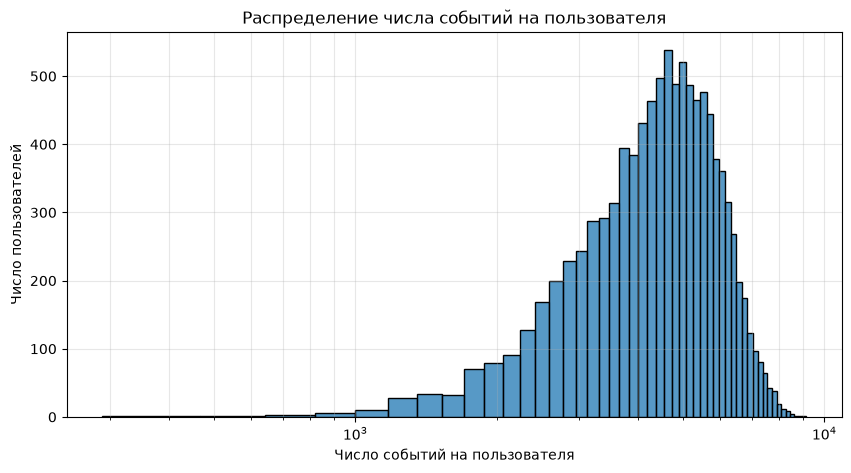

In [13]:
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(events_per_user, bins=50)

plt.xscale("log")
plt.xlabel("Число событий на пользователя")
plt.ylabel("Число пользователей")
plt.title("Распределение числа событий на пользователя")
plt.grid(True, which="both", alpha=0.3)

plt.show()

In [27]:
active_weeks_per_user = (
    train.groupby("user_id")["week"]
    .nunique()
)
active_weeks_per_user.head()

user_id
20125     25
32170     25
33549     25
48637     25
124907    25
Name: week, dtype: int64

In [28]:
distribution = active_weeks_per_user.value_counts()

print(distribution)

week
25    9645
24     213
23      72
22      37
21      19
20       8
19       5
18       1
Name: count, dtype: int64


In [29]:
active_weeks_per_user = (
    train.groupby("user_id")["week"]
    .nunique().reset_index(name="active_weeks")
)

In [38]:
users_meta_indexed = users_meta.set_index("user_id")

active_weeks_per_user["age"] = (
    active_weeks_per_user["user_id"]
    .map(users_meta_indexed["age"])
)

active_weeks_per_user["gender"] = (
    active_weeks_per_user["user_id"]
    .map(users_meta_indexed["gender"])
)

active_weeks_per_user["geo"] = (
    active_weeks_per_user["user_id"]
    .map(users_meta_indexed["geo"])
)

In [39]:
aw = active_weeks_per_user

In [40]:
aw.head()

,user_id,active_weeks,age,gender,geo
0,20125,25,35,2,78
1,32170,25,26,1,69
2,33549,25,28,1,79
3,48637,25,56,2,28
4,124907,25,35,2,57


In [43]:
aw.groupby("active_weeks")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
active_weeks,,,,,,,,
18,1.0000,32.0000,NaN,32.0000,32.0000,32.0000,32.0000,32.0000
19,5.0000,41.8000,6.3797,36.0000,36.0000,41.0000,45.0000,51.0000
20,8.0000,32.2500,12.2329,18.0000,20.2500,33.0000,42.5000,47.0000
21,19.0000,39.9474,12.6863,18.0000,31.5000,39.0000,47.0000,69.0000
22,37.0000,32.1351,11.1484,19.0000,22.0000,32.0000,41.0000,54.0000
23,72.0000,33.2639,12.6502,18.0000,23.0000,31.0000,37.2500,70.0000
24,213.0000,34.0892,11.4939,18.0000,25.0000,33.0000,40.0000,69.0000
25,"9,645.0000",34.5473,10.9181,18.0000,26.0000,33.0000,41.0000,70.0000


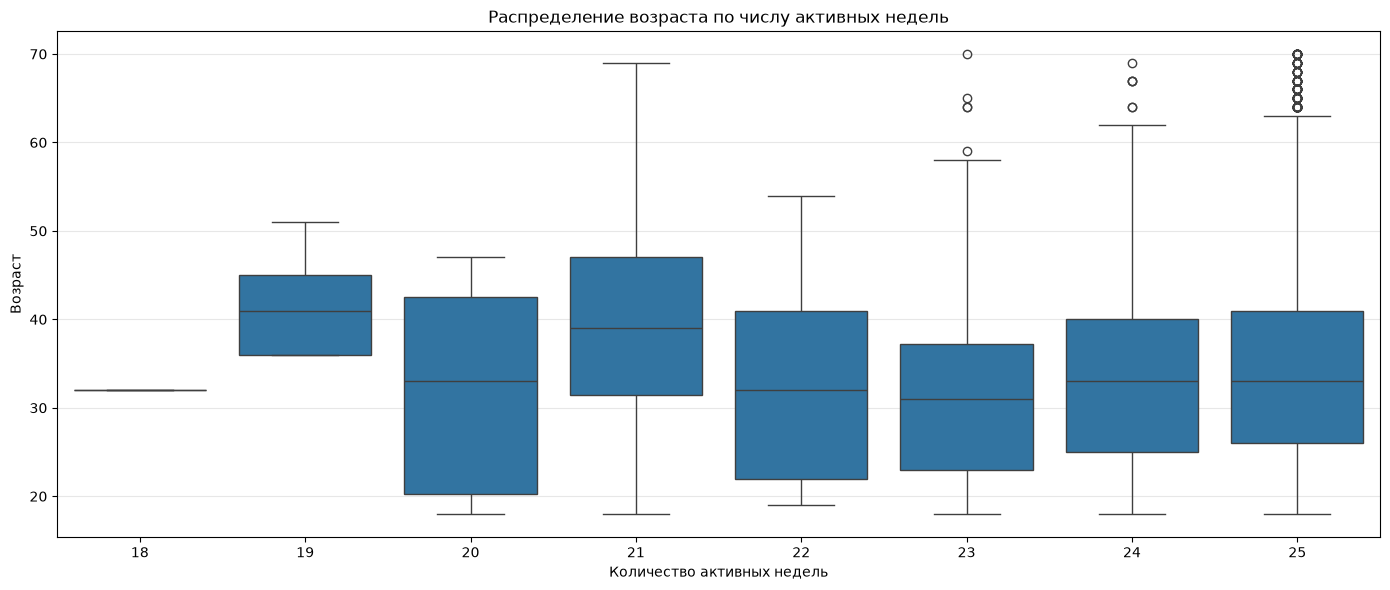

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=active_weeks_per_user,
    x="active_weeks",
    y="age"
)

plt.xlabel("Количество активных недель")
plt.ylabel("Возраст")
plt.title("Распределение возраста по числу активных недель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

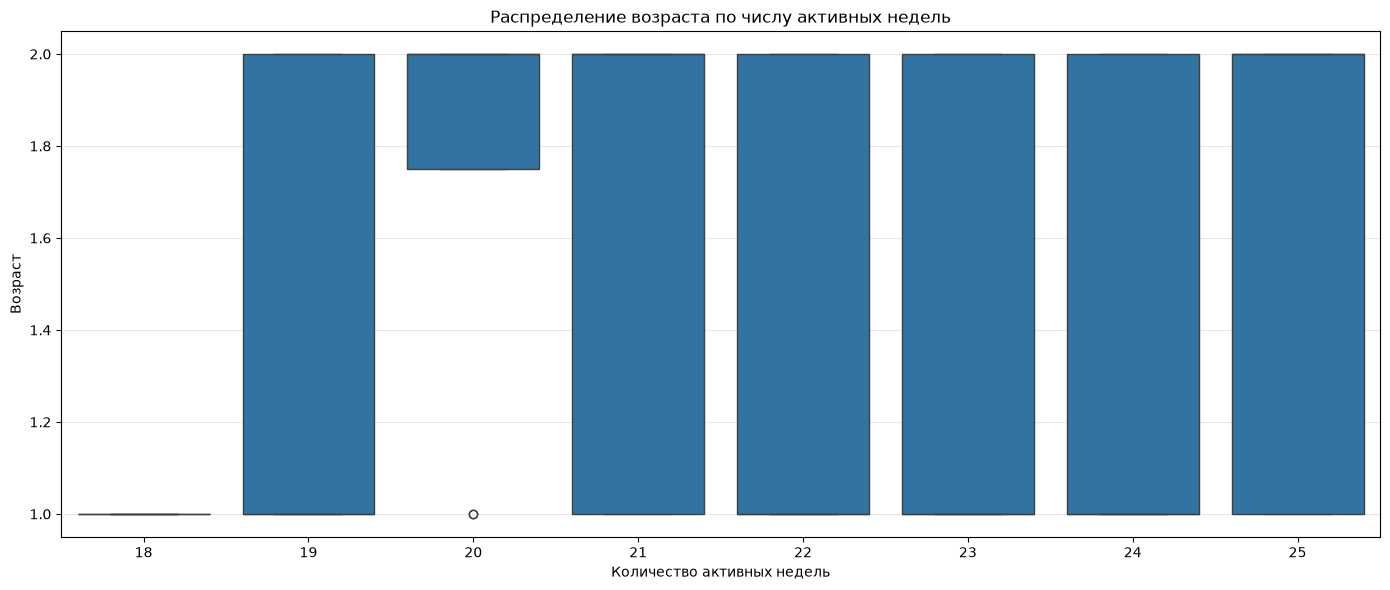

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=active_weeks_per_user,
    x="active_weeks",
    y="gender"
)

plt.xlabel("Количество активных недель")
plt.ylabel("Возраст")
plt.title("Распределение возраста по числу активных недель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

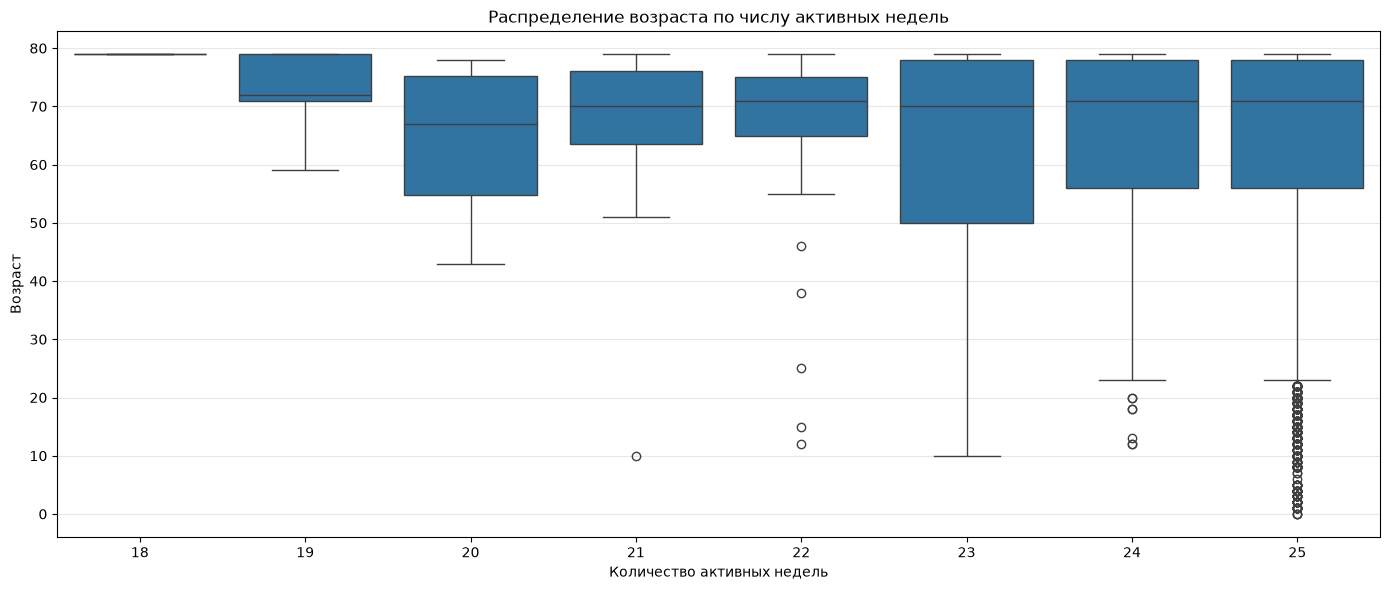

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=active_weeks_per_user,
    x="active_weeks",
    y="geo"
)

plt.xlabel("Количество активных недель")
plt.ylabel("Возраст")
plt.title("Распределение возраста по числу активных недель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
platform_stats = (
    train.groupby("platform", dropna=False)
    .agg(
        events_count=("timespent", "size"),
        mean_timespent=("timespent", "mean"),
        median_timespent=("timespent", "median"),
        q25_timespent=("timespent", lambda x: x.quantile(0.25)),
        q75_timespent=("timespent", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

platform_stats["share_percent"] = (
    platform_stats["events_count"]
    / platform_stats["events_count"].sum()
    * 100
)

platform_stats.round(2)

,platform,events_count,mean_timespent,median_timespent,q25_timespent,q75_timespent,share_percent
0,0,30754546,15.1600,6.0000,2.0000,18.0000,65.3400
1,1,12822322,16.1100,7.0000,2.0000,19.0000,27.2400
2,2,2498844,15.8800,7.0000,2.0000,20.0000,5.3100
3,3,564612,16.5200,7.0000,3.0000,21.0000,1.2000
4,4,4512,19.1900,6.0000,2.0000,20.0000,0.0100
5,5,449,17.8000,6.0000,2.0000,21.0000,0.0000
6,6,204578,16.3500,7.0000,2.0000,21.0000,0.4300
7,7,94171,15.6100,6.0000,3.0000,18.0000,0.2000
8,8,115330,17.2600,7.0000,3.0000,22.0000,0.2500
9,9,4254,17.2000,7.0000,3.0000,22.0000,0.0100


In [52]:
platform_stats = (
    train.groupby("agent", dropna=False)
    .agg(
        events_count=("timespent", "size"),
        mean_timespent=("timespent", "mean"),
        median_timespent=("timespent", "median"),
        q25_timespent=("timespent", lambda x: x.quantile(0.25)),
        q75_timespent=("timespent", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

platform_stats["share_percent"] = (
    platform_stats["events_count"]
    / platform_stats["events_count"].sum()
    * 100
)

platform_stats.round(2)

,agent,events_count,mean_timespent,median_timespent,q25_timespent,q75_timespent,share_percent
0,0,30778150,15.1600,6.0000,2.0000,18.0000,65.3900
1,1,13481082,16.1200,7.0000,2.0000,20.0000,28.6400
2,2,2674028,15.9200,7.0000,2.0000,20.0000,5.6800
3,3,2223,20.4700,7.0000,2.0000,21.0000,0.0000
4,4,1883,17.5500,6.0000,2.0000,18.0000,0.0000
5,5,158,17.8700,7.5000,2.0000,20.0000,0.0000
6,6,115353,17.2600,7.0000,3.0000,22.0000,0.2500
7,7,146,11.0800,4.0000,2.0000,10.0000,0.0000
8,8,145,23.6300,13.0000,4.0000,32.0000,0.0000
9,9,72,14.7900,4.0000,1.0000,13.2500,0.0000


In [53]:
platform_stats = (
    train.groupby("place", dropna=False)
    .agg(
        events_count=("timespent", "size"),
        mean_timespent=("timespent", "mean"),
        median_timespent=("timespent", "median"),
        q25_timespent=("timespent", lambda x: x.quantile(0.25)),
        q75_timespent=("timespent", lambda x: x.quantile(0.75))
    )
    .reset_index()
)

platform_stats["share_percent"] = (
    platform_stats["events_count"]
    / platform_stats["events_count"].sum()
    * 100
)

platform_stats.round(2)

,place,events_count,mean_timespent,median_timespent,q25_timespent,q75_timespent,share_percent
0,0,12414925,13.4700,6.0000,2.0000,16.0000,26.3800
1,1,33301627,16.4000,6.0000,2.0000,20.0000,70.7500
2,2,903596,9.5200,3.0000,2.0000,8.0000,1.9200
3,3,46374,23.2700,10.0000,3.0000,29.0000,0.1000
4,4,193587,7.0300,3.0000,1.0000,7.0000,0.4100
...,...,...,...,...,...,...,...
19,19,13,4.3800,3.0000,2.0000,7.0000,0.0000
20,20,421,26.4000,8.0000,2.0000,33.0000,0.0000
21,21,259,24.4200,7.0000,2.0000,26.5000,0.0000
22,22,178,18.0400,8.0000,3.0000,24.0000,0.0000


## 3. Айтемы и авторы
- Распределение популярности видео (лог-лог). Какая доля событий приходится на топ-1% / топ-10% видео? Посчитай **Gini**.
- Сколько видео имеют < 5 взаимодействий? (Кандидаты на фильтрацию / проблема для ID-эмбеддингов.)
- **Жизненный цикл видео:** для каждого видео — первая и последняя неделя, сколько недель «живёт». Короткие видео быстро устаревают?
- Авторы: сколько видео на автора, насколько популярность сконцентрирована у топ-авторов.
- `duration`: распределение. В каких единицах? (Сверь с `timespent`.)

In [18]:
# TODO

**Вывод:** ...

## 4. Сигналы обратной связи → определение позитива
Главный раздел. Итог — **одно формальное правило «что такое позитив»** с обоснованием.
- Распределение `timespent` и **доли досмотра** `timespent / duration` (обрати внимание на значения > 1 — пересмотры/зацикливание — и на обрезку на 255).
- Частота явных реакций: like, dislike, share, bookmark, click_on_author, open_comments.
- Как связаны явные реакции с долей досмотра? (Например: средний completion у лайкнутых vs остальных.) Это аргумент для выбора порога.
- Предложи 2–3 кандидата правила позитива и для каждого посчитай: долю позитивов, среднее число позитивов на юзера, число айтемов, у которых остался хотя бы один позитив.

In [19]:
# TODO

**Вывод:**
- Правило позитива: ...
- Доля позитивов: ...
- Dislike трактуем как: ...

## 5. Последовательности
- Отсортируй события юзера по `(week, pos_in_week)` — это его последовательность. Проверь, что порядок осмысленный (например, повторные просмотры одного видео идут «рядом»?).
- Длины последовательностей **после применения правила позитива** из раздела 4. Квантили → выбор `max_len` (какую долю истории покрывают 50 / 200 / 500 последних событий?).
- **Повторы:** как часто юзер повторно взаимодействует с тем же видео? Какая доля позитивов на неделе N приходится на видео, которые юзер уже видел раньше? → решение про фильтрацию просмотренного.

In [20]:
# TODO

**Вывод:**
- Стартовый `max_len`: ...
- Фильтровать просмотренное: да / нет, потому что ...

## 6. Время, сплит и холодный старт
Теперь можно смотреть val (неделя 25) и test (неделя 26).
- Число событий / активных юзеров / уникальных видео по неделям. Есть ли тренды или провалы?
- **Дрейф популярности:** пересечение топ-100 видео соседних недель (Jaccard). Насколько популярное «на прошлой неделе» предсказывает следующую? → какой MostPop-бейзлайн брать.
- **Холодные айтемы:** какая доля айтемов val/test и какая доля **позитивных событий** val/test приходится на видео, которых нет в train? Это **потолок Recall** для любой ID-based модели — посчитай его явно.
- **Холодные юзеры:** все ли юзеры val/test есть в train?

In [21]:
# TODO

**Вывод:**
- Потолок Recall из-за холодных айтемов: val ..., test ...
- Бейзлайн популярности: ...

## 7. Итог: решения для этапа подготовки данных
| Решение | Значение | Обоснование (раздел) |
|---|---|---|
| Позитив | | 4 |
| Dislike | | 4 |
| Учить на всех событиях / только на позитивах | | 4, 5 |
| `max_len` | | 5 |
| Фильтрация просмотренного | | 5 |
| Фильтрация редких айтемов | | 3 |
| Потолок Recall (cold items) | | 6 |
| Сильный popularity-бейзлайн | | 6 |